# Tutorial for the neutrino flux options

(c) Isabel Goos, Yael Deniz, Nobuaki Fuji

05/08/2026


## Introduction


<div style="font-family: 'Arial'; font-size: 16px; line-height: 1.6;">The original objective of this notebook is to test the implementation of the neutrino flux options. 
But it can also serve as a tutorial to better understand the options we cover regarding the neutrino flux.  <br>

Flexopt offers the option to simulate neutrino oscillations through the Earth, which are relevant at neutrino energies between around 1 GeV and 100 GeV.
Neutrinos in this energy range are predominantly produced in the Earth's atmosphere.  <br>

The state-of-the-art model of this atmopheric neutrino flux has been developed by <span style="color:purple">**Honda**</span> et al. ([arXiv:1502.03916](https://arxiv.org/pdf/1502.03916)). 
Their well-established data-driven model has been used by the neutrino community for over a decade, which is why it is chosen as the default model in Flexopt.

In recent years, with new muon datasets available, several groups across the globe have committed to updating this model.

One such atmopheric neutrino flux that is openly available is the <span style="color:purple">**Daemonflux**</span> model ([arXiv2303.00022](https://arxiv.org/pdf/2303.00022)), which has some advantages and some disadvantages when compared to the Honda model.

While the Honda model is available in the form of fixed tables and for a predefined set of options, the Daemonflux has 24 parameters that the user can vary.
Furthermore, Honda provides a very coarse description of systematic uncertainties, whereas in Daemonflux systematic uncertainties are propagated for each parameter choice.
However, a considerable disadvantage of the Daemonflux model is that it does not provide reliable results below ~5 GeV.
Furthermore, Honda provides neutrino fluxes for 9 detector locations whereas Daemonflux only covers the IceCube location at the South Pole (regarding Earth-crossing neutrinos). 
The choice of location matters because the magnetic field of the Earth deviates low energy charged particles produced in cosmic ray air showers.
The Daemonflux developers are actively working on a reliable extension of their model to energies below 5 GeV and the incorporation of new detector locations.

Very recently, <span style="color:purple">**Cheng**</span> et al. made publicly available a new atmospheric neutrino flux model specifically targeting the low-energy regime, extending down to 100 MeV ([arXiv2607.08310](https://arxiv.org/pdf/2607.08310)). 
Its main strength is its focus on this low-energy range. 
The model builds on the Honda flux model and therefore shares its limitations in the treatment of systematic uncertainties and the coarseness of the energy and angular binnings, as well as its advantage of providing flux predictions for multiple detector locations.

Beyond these models, the <span style="color:purple">**Bartol**</span> flux is currently being updated ([slides can be found here](https://indico.global/event/13955/contributions/128326/attachments/59268/114167/owan25_20250603_YY.pdf)). 
Its main advantages are its extension to energies below 5 GeV and the inclusion of a variety of detector locations. 
However, it is not yet publicly available and, being provided in Honda-style tables, its associated uncertainties may have the same issues as the uncertainties for the Honda model. 

Neither model provides tau-neutrino or -antineutrino fluxes since they are negligible.

The astrophysical neutrino flux for neutrino absorption tomography is not yet implemented in Flexopt.
</div>


## Default parameters

<div style="font-family: 'Arial'; font-size: 16px; line-height: 1.6;">The tables below list the parameters of each supported neutrino flux model together with their default values, meaning, and alternative options.
</div>

### Honda

| Parameter | Default | Meaning | Alternatives | 
|---|---|---|---|
| `location` | `:gran_sasso` | Site for which the flux was computed. | `:kamioka`, `:sudbury`, `:frejus`, `:ino`, `:south_pole`, `:pythasalmi`, `:homestake`, ` :juno` |
| `season` | `:all_year` | Flux is averaged over the given season. | `:march_may`, `:june_aug`, `:sept_nov`, `:dec_feb` |
| `angles_separation` | `:averaged_ϕ` | Flux is averaged over ϕ, ϕ and θ, or not at all. | `:variable_ϕ`, `:averaged_ϕθ` |
| `solar_activity` | `:minimum` | Solar activity. | `:maximum` |
| `mountain_overburden` | `:without` | Rock overburden above the detector. | `:with` |

### Daemonflux

| Parameter | Default | Meaning | Alternatives |
|---|---|---|---|
| `flux_mode` | `:total` | Flux mode. | `:conventional` |
| `return_uncertainties` | `false` | Only the central flux values are returned, without uncertainties. | `true` |
| `params` | `nothing` | The model's built-in parameter values are used, with no overrides. | "K+_158G", "K+_2P", "K+_31G", "K-_158G", "K-_2P", "K-_31G", "n_158G", "n_2P", "p_158G", "p_2P", "pi+_158G", "pi+_20T", "pi+_2P", "pi+_31G", "pi-_158G", "pi-_20T", "pi-_2P", "pi-_31G", "GSF_1", "GSF_2", "GSF_3", "GSF_4", "GSF_5", "GSF_6" |

Clarifications:
- `:conventional`: only the conventional component, i.e. neutrinos from the decays of pions and kaons. This is the dominant contribution at lower energies. The prompt component, from the decays of short-lived charmed hadrons, is left out.
- `:total`: conventional and prompt components together.
- `params` is optional. To override internal Daemonflux parameters, pass a dictionary that maps parameter names (for example `"K+_158G"`) to their values. Only the listed parameters are changed. Later in this notebook, we show how to choose these parameters.
- `use_calibration` is set to true so that the Daemonflux calibration is used by default.
- Reminder: IceCube location is used, since it is the only one available for now.

### Cheng

| Parameter | Default | Meaning | Alternatives |
|---|---|---|---|
| `location` | `:orca` | Site for which the flux was computed. | `:cjpl`, `:dune`, `:icecube`, `:juno`, `:superk`, `:trident ` |
| `season` | `:all_year` | Flux is averaged over the given season. | `:march_may`, `:june_aug`, `:sept_nov`, `:dec_feb` |
| `angles_separation` | `:averaged_ϕ` | Flux is averaged over ϕ, ϕ and θ, or not at all. | `:variable_ϕ`, `:averaged_ϕθ` |
| `solar_activity` | `:minimum` | Solar activity. | `:maximum` |
| `muon_propa_earth` | `:with` | Muon propagation in the Earth is modeled or not. | `:without` |


## Let's start the tutorial/test!

In [35]:
include("config.jl")
include("generate_neutrino_flux.jl");


In [2]:
using CairoMakie   
using Statistics


### Setting the default neutrino flux model and its parameters

In this section, we describe how DEFAULT_NUFLUX_MODEL and DEFAULT_NUFLUX_PARAMS are set.

Actually, Flexopt already defines default values. Let’s examine them to verify the statements made in the text and table above:

In [3]:
@show DEFAULT_NUFLUX_MODEL[]
@show DEFAULT_NUFLUX_PARAMS[];

DEFAULT_NUFLUX_MODEL[] = :Honda
DEFAULT_NUFLUX_PARAMS[] = HondaParameters(:gran_sasso, :all_year, :averaged_ϕ, :minimum, :without, false)


If we do the following, nothing changes (default Flexopt definitions are merely confirmed):

In [4]:
set_default_neutrino_flux!()

# Inspect the selected neutrino flux model, parameter type, and parameters.
@show DEFAULT_NUFLUX_MODEL[]
@show DEFAULT_NUFLUX_PARAMS[]
@show DEFAULT_NUFLUX_PARAMS[].location
@show DEFAULT_NUFLUX_PARAMS[].solar_activity;


DEFAULT_NUFLUX_MODEL[] = :Honda
DEFAULT_NUFLUX_PARAMS[] = HondaParameters(:gran_sasso, :all_year, :averaged_ϕ, :minimum, :without, false)
(DEFAULT_NUFLUX_PARAMS[]).location = :gran_sasso
(DEFAULT_NUFLUX_PARAMS[]).solar_activity = :minimum


How to set the default neutrino flux and parameters, with the location parameter updated to "kamioka":

In [5]:
set_default_neutrino_flux!(location=:kamioka)     

@show DEFAULT_NUFLUX_MODEL[]
@show DEFAULT_NUFLUX_PARAMS[]
@show DEFAULT_NUFLUX_PARAMS[].location
@show DEFAULT_NUFLUX_PARAMS[].solar_activity;


DEFAULT_NUFLUX_MODEL[] = :Honda
DEFAULT_NUFLUX_PARAMS[] = HondaParameters(:kamioka, :all_year, :averaged_ϕ, :minimum, :without, false)
(DEFAULT_NUFLUX_PARAMS[]).location = :kamioka
(DEFAULT_NUFLUX_PARAMS[]).solar_activity = :minimum


Note that if you want to update multiple parameters, you must do so in a single call:

In [6]:
set_default_neutrino_flux!(location=:kamioka, solar_activity=:maximum)          

@show DEFAULT_NUFLUX_MODEL[]
@show DEFAULT_NUFLUX_PARAMS[]
@show DEFAULT_NUFLUX_PARAMS[].location
@show DEFAULT_NUFLUX_PARAMS[].solar_activity;

# don't do:
# set_default_neutrino_flux!(location=:kamioka)    
# set_default_neutrino_flux!(solar_activity=:maximum)    


DEFAULT_NUFLUX_MODEL[] = :Honda
DEFAULT_NUFLUX_PARAMS[] = HondaParameters(:kamioka, :all_year, :averaged_ϕ, :maximum, :without, false)
(DEFAULT_NUFLUX_PARAMS[]).location = :kamioka
(DEFAULT_NUFLUX_PARAMS[]).solar_activity = :maximum


If an invalid parameter key or value is provided (e.g., place instead of location, or medium for solar activity), the valid options are displayed to help you quickly correct the configuration and set valid defaults for the neutrino flux.

In [7]:
set_default_neutrino_flux!(place=:kamioka)          


LoadError: ArgumentError: Unknown HondaParameters: [:place]. Valid: [:location, :season, :angles_separation, :solar_activity, :mountain_overburden, :return_uncertainties].

In [ ]:
set_default_neutrino_flux!(solar_activity=:medium)          


LoadError: ArgumentError: Unsupported Honda solar activity :medium. Valid: [:minimum, :maximum].

Let's check another model altogether:

In [8]:
set_default_neutrino_flux!(:Cheng)   

@show DEFAULT_NUFLUX_MODEL[]
@show DEFAULT_NUFLUX_PARAMS[];


DEFAULT_NUFLUX_MODEL[] = :Cheng
DEFAULT_NUFLUX_PARAMS[] = ChengParameters(:orca, :all_year, :averaged_ϕ, :minimum, :with, false)


Note that if you forget to give the symbol of the model you are interested in, and give it as a string instead, the method still works:

In [9]:
set_default_neutrino_flux!("Cheng")   

@show DEFAULT_NUFLUX_MODEL[]
@show DEFAULT_NUFLUX_PARAMS[];


DEFAULT_NUFLUX_MODEL[] = :Cheng
DEFAULT_NUFLUX_PARAMS[] = ChengParameters(:orca, :all_year, :averaged_ϕ, :minimum, :with, false)


In [10]:
set_default_neutrino_flux!(:Cheng, location="juno")   
# set_default_neutrino_flux!(:Cheng, location=:juno) works, too

@show DEFAULT_NUFLUX_MODEL[]
@show DEFAULT_NUFLUX_PARAMS[].location;


DEFAULT_NUFLUX_MODEL[] = :Cheng
(DEFAULT_NUFLUX_PARAMS[]).location = :juno


What happens if we don't put anything in the parenthesis now?:

In [11]:
set_default_neutrino_flux!()

@show DEFAULT_NUFLUX_MODEL[]
@show DEFAULT_NUFLUX_PARAMS[].location;


DEFAULT_NUFLUX_MODEL[] = :Honda
(DEFAULT_NUFLUX_PARAMS[]).location = :gran_sasso


Notice 2 things:
- The default neutrino flux model is now `:Honda`, which is our recommended choice (and Flexopt default). 
- The location was reset to `:gran_sasso`. This happens because calling  `set_default_neutrino_flux!` without any keyword arguments resets the parameters to their default values for the selected neutrino flux model, which in this case is `:Honda`.

To summarize, use the `set_default_neutrino_flux!` function to set your preferred default neutrino flux model and parameters. If you are unsure which model is currently active or how it is configured, you can inspect its settings using the approach demonstrated in the cells above to verify that it matches your intended configuration.

Sometimes the webpage containing the Honda models may be down. If this happens, try the other models while waiting for the website to become available again.


### Producing a neutrino flux

In addition to DEFAULT_NUFLUX_MODEL and DEFAULT_NUFLUX_PARAMS, the energy and angular bin centers must be specified to compute the neutrino flux.

Flexopt is designed to work 2 ways. 
- If you defined DEFAULT_NUFLUX_MODEL and DEFAULT_NUFLUX_PARAMS using the set_default_neutrino_flux! function as described above, you just need to provide the energy and angular bin centers to produce a neutrino flux. Energies are always given in GeV. 
- If you still want to modify DEFAULT_NUFLUX_MODEL and/or DEFAULT_NUFLUX_PARAMS, you can still do it at this point.

We will show how both approaches work in the next few cells.


Let's first assume that we already settled on a DEFAULT_NUFLUX_MODEL and a DEFAULT_NUFLUX_PARAMS (in this case, if you have run all the cells above, it should be Honda with its default parameters). In this case, we can define the energy and angular binning as follows:

In [12]:
# Compute energy bin centers

minEnergy = 0.1
maxEnergy = 10000.0
numEnergyBins = 15

# Use logarithmic binning to resolve low energies across a wide energy range
energies = logrange(minEnergy, maxEnergy, numEnergyBins + 1) # [GeV]

# Compute geometric means to obtain the bin centers
energies = sqrt.(energies[1:end-1] .* energies[2:end]) # [GeV]

# Compute angular bin centers in cos(θ)

mincosθ = -1
maxcosθ = 1
numAngleBins = 20

# Use linear binning in cos(θ)
cosθs = range(mincosθ, maxcosθ, numAngleBins + 1)

# Compute arithmetic means to obtain the bin centers
cosθs = (cosθs[1:end-1] .+ cosθs[2:end]) ./ 2;


#### Honda model

We can now generate a neutrino flux using the binning scheme defined above and the produce_neutrino_flux function, as shown below. Note that all model parameters are printed to make the configuration of the generated flux explicit.

In [13]:
nuflux = produce_neutrino_flux(Dict{String, Any}(
    "bin_centers_arrays"   => (energies, cosθs),
    "return_uncertainties" => true
))

flux_νe      = nuflux["Nue_flux"]
flux_νμ      = nuflux["NuMu_flux"]
flux_aνe     = nuflux["AntiNue_flux"]
flux_aνμ     = nuflux["AntiNuMu_flux"]

flux_νe_err  = nuflux["Nue_flux_err"]
flux_νμ_err  = nuflux["NuMu_flux_err"]
flux_aνe_err = nuflux["AntiNue_flux_err"]
flux_aνμ_err = nuflux["AntiNuMu_flux_err"]

E            = nuflux["Energies"]       
cosθ         = nuflux["cosθs"]; 


solar_activity => minimum
location => gran_sasso
model => Honda
bin_centers_arrays => ([0.14677992676220697, 0.31622776601683794, 0.6812920690579614, 1.4677992676220695, 3.1622776601683795, 6.812920690579613, 14.677992676220697, 31.622776601683796, 68.12920690579612, 146.77992676220694, 316.22776601683796, 681.2920690579613, 1467.7992676220695, 3162.2776601683795, 6812.920690579613], -0.95:0.1:0.95)
return_uncertainties => true
mountain_overburden => without
season => all_year
angles_separation => averaged_ϕ


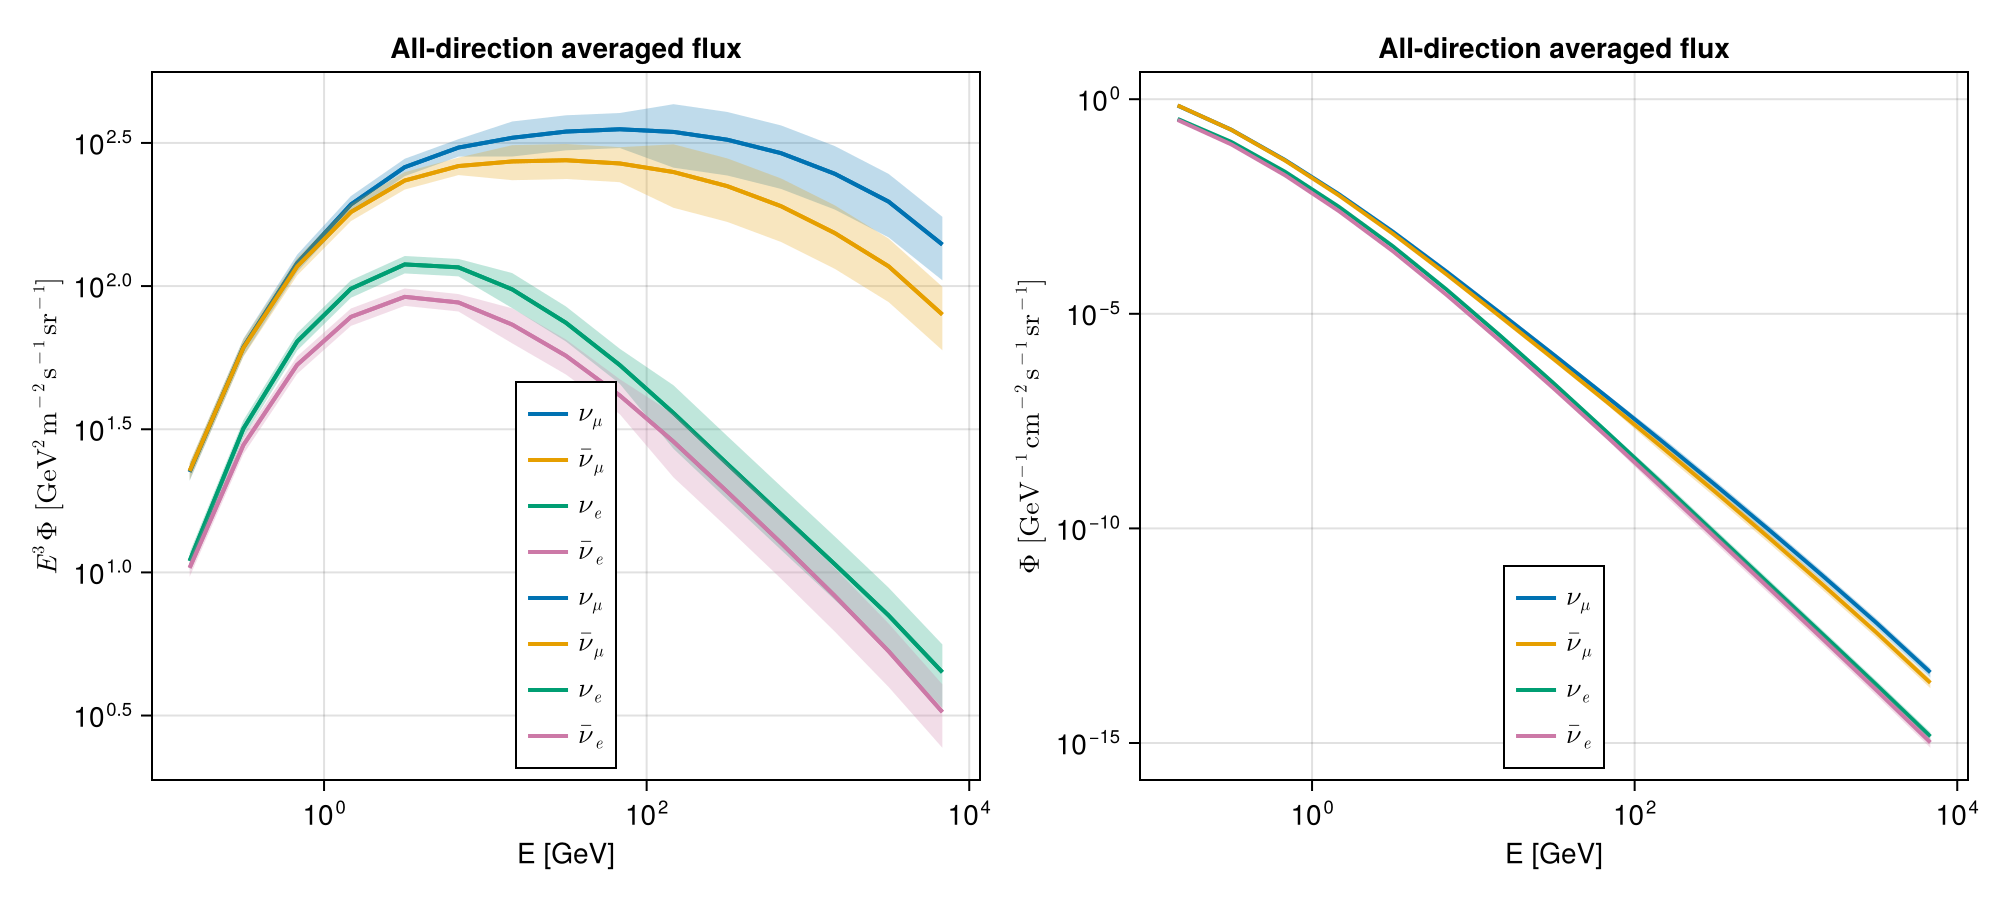

In [14]:

flux_list     = [flux_νμ,     flux_aνμ,     flux_νe,     flux_aνe]
flux_err_list = [flux_νμ_err, flux_aνμ_err, flux_νe_err, flux_aνe_err]
labels        = [L"\nu_\mu", L"\bar\nu_\mu", L"\nu_e", L"\bar\nu_e"]
colors        = Makie.wong_colors()[1:4]

fig1 = Figure(size = (1000, 450))

ax1 = Axis(fig1[1, 1]; 
           xscale = log10, yscale = log10,
           xlabel = "E [GeV]",
           ylabel = L"E^3\,\Phi\ [\mathrm{GeV^{2}\,m^{-2}\,s^{-1}\,sr^{-1}}]",
           title  = "All-direction averaged flux")
for (label, flux) in zip(labels, flux_list)
    lines!(ax1, E, E .^ 3 .* vec(mean(flux, dims = 2)); label = label, linewidth = 2)
end
for (label, flux, err, c) in zip(labels, flux_list, flux_err_list, colors)
    φ  = vec(mean(flux, dims = 2))
    Δφ = vec(mean(err,  dims = 2))
    band!(ax1, E, E .^ 3 .* (φ .- Δφ), E .^ 3 .* (φ .+ Δφ); color = (c, 0.25))
    lines!(ax1, E, E .^ 3 .* φ; label = label, linewidth = 2, color = c)
end
axislegend(ax1; position = :cb)

ax2 = Axis(fig1[1, 2]; 
           xscale = log10, yscale = log10,
           xlabel = "E [GeV]",
           ylabel = L"\Phi\ [\mathrm{GeV^{-1}\,cm^{-2}\,s^{-1}\,sr^{-1}}]",
           title  = "All-direction averaged flux")
for (label, flux, err, c) in zip(labels, flux_list, flux_err_list, colors)
    φ  = vec(mean(flux, dims = 2)) ./ 10000.
    Δφ = vec(mean(err,  dims = 2)) ./ 10000.
    band!(ax2, E, φ .- Δφ, φ .+ Δφ; color = (c, 0.25))
    lines!(ax2, E, φ; label = label, linewidth = 2, color = c)
end
axislegend(ax2; position = :cb)

fig1


The figure on the left can be compared with figure 3 in [arXiv:1502.03916](https://arxiv.org/pdf/1502.03916) and the figure on the right with figure 3 in ["Sensitivity of neutrino oscillations to the Earth’s interior properties"](https://www.sciencedirect.com/science/article/pii/S0012821X26005340). Indeed, Flexopt is working well.

#### Cheng model

To generate the Cheng neutrino flux using its default parameters and the same binning as above, we proceed as follows:

In [24]:
nuflux = produce_neutrino_flux(Dict{String, Any}(
    "model"                => :Cheng,
    "return_uncertainties" => true,
    "bin_centers_arrays"   => (energies, cosθs)
))

flux_νe  = nuflux["Nue_flux"]
flux_νμ  = nuflux["NuMu_flux"]
flux_aνe = nuflux["AntiNue_flux"]
flux_aνμ = nuflux["AntiNuMu_flux"]

flux_νe_err  = nuflux["Nue_flux_err"]
flux_νμ_err  = nuflux["NuMu_flux_err"]
flux_aνe_err = nuflux["AntiNue_flux_err"]
flux_aνμ_err = nuflux["AntiNuMu_flux_err"]

E        = nuflux["Energies"]
cosθ     = nuflux["cosθs"]; 


solar_activity => minimum
location => orca
model => Cheng
bin_centers_arrays => ([0.14677992676220697, 0.31622776601683794, 0.6812920690579614, 1.4677992676220695, 3.1622776601683795, 6.812920690579613, 14.677992676220697, 31.622776601683796, 68.12920690579612, 146.77992676220694, 316.22776601683796, 681.2920690579613, 1467.7992676220695, 3162.2776601683795, 6812.920690579613], -0.95:0.1:0.95)
return_uncertainties => true
season => all_year
angles_separation => averaged_ϕ
muon_propa_earth => with


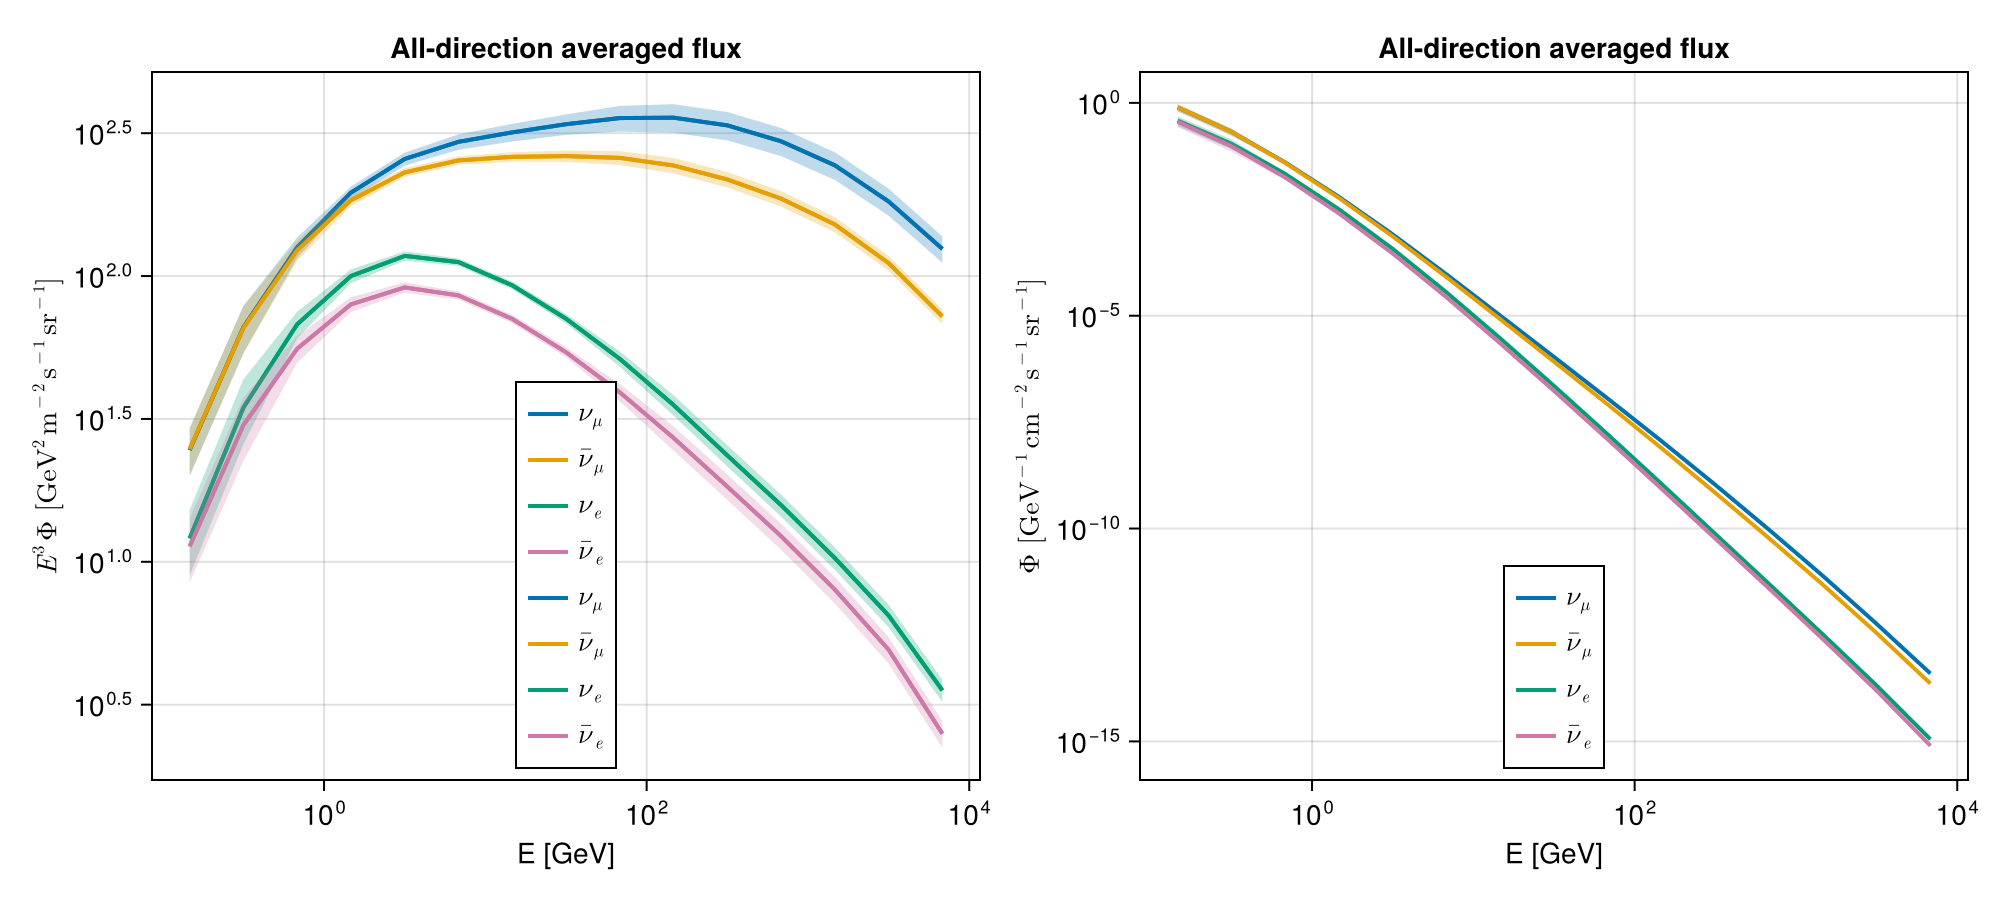

In [25]:

flux_list     = [flux_νμ,     flux_aνμ,     flux_νe,     flux_aνe]
flux_err_list = [flux_νμ_err, flux_aνμ_err, flux_νe_err, flux_aνe_err]
labels        = [L"\nu_\mu", L"\bar\nu_\mu", L"\nu_e", L"\bar\nu_e"]
colors        = Makie.wong_colors()[1:4]

fig2 = Figure(size = (1000, 450))

ax1 = Axis(fig2[1, 1]; 
           xscale = log10, yscale = log10,
           xlabel = "E [GeV]",
           ylabel = L"E^3\,\Phi\ [\mathrm{GeV^{2}\,m^{-2}\,s^{-1}\,sr^{-1}}]",
           title  = "All-direction averaged flux")
for (label, flux) in zip(labels, flux_list)
    lines!(ax1, E, E .^ 3 .* vec(mean(flux, dims = 2)); label = label, linewidth = 2)
end
for (label, flux, err, c) in zip(labels, flux_list, flux_err_list, colors)
    φ  = vec(mean(flux, dims = 2))
    Δφ = vec(mean(err,  dims = 2))
    band!(ax1, E, E .^ 3 .* (φ .- Δφ), E .^ 3 .* (φ .+ Δφ); color = (c, 0.25))
    lines!(ax1, E, E .^ 3 .* φ; label = label, linewidth = 2, color = c)
end
axislegend(ax1; position = :cb)

ax2 = Axis(fig2[1, 2]; 
           xscale = log10, yscale = log10,
           xlabel = "E [GeV]",
           ylabel = L"\Phi\ [\mathrm{GeV^{-1}\,cm^{-2}\,s^{-1}\,sr^{-1}}]",
           title  = "All-direction averaged flux")
for (label, flux, err, c) in zip(labels, flux_list, flux_err_list, colors)
    φ  = vec(mean(flux, dims = 2)) ./ 10000.
    Δφ = vec(mean(err,  dims = 2)) ./ 10000.
    band!(ax2, E, φ .- Δφ, φ .+ Δφ; color = (c, 0.25))
    lines!(ax2, E, φ; label = label, linewidth = 2, color = c)
end
axislegend(ax2; position = :cb)

fig2


Once again, comparing these figures with those published in the literature, we find good agreement. Note that, at energies above around 1 GeV, the errors in the Cheng model are generally smaller than in the Honda model. At low energies, this behavior is reversed.

Note that we did not modify the defaults DEFAULT_NUFLUX_MODEL and DEFAULT_NUFLUX_PARAMS this way:

In [26]:
@show DEFAULT_NUFLUX_MODEL[]
@show DEFAULT_NUFLUX_PARAMS[];

DEFAULT_NUFLUX_MODEL[] = :Honda
DEFAULT_NUFLUX_PARAMS[] = HondaParameters(:gran_sasso, :all_year, :averaged_ϕ, :minimum, :without, false)


Let's look at the errors:

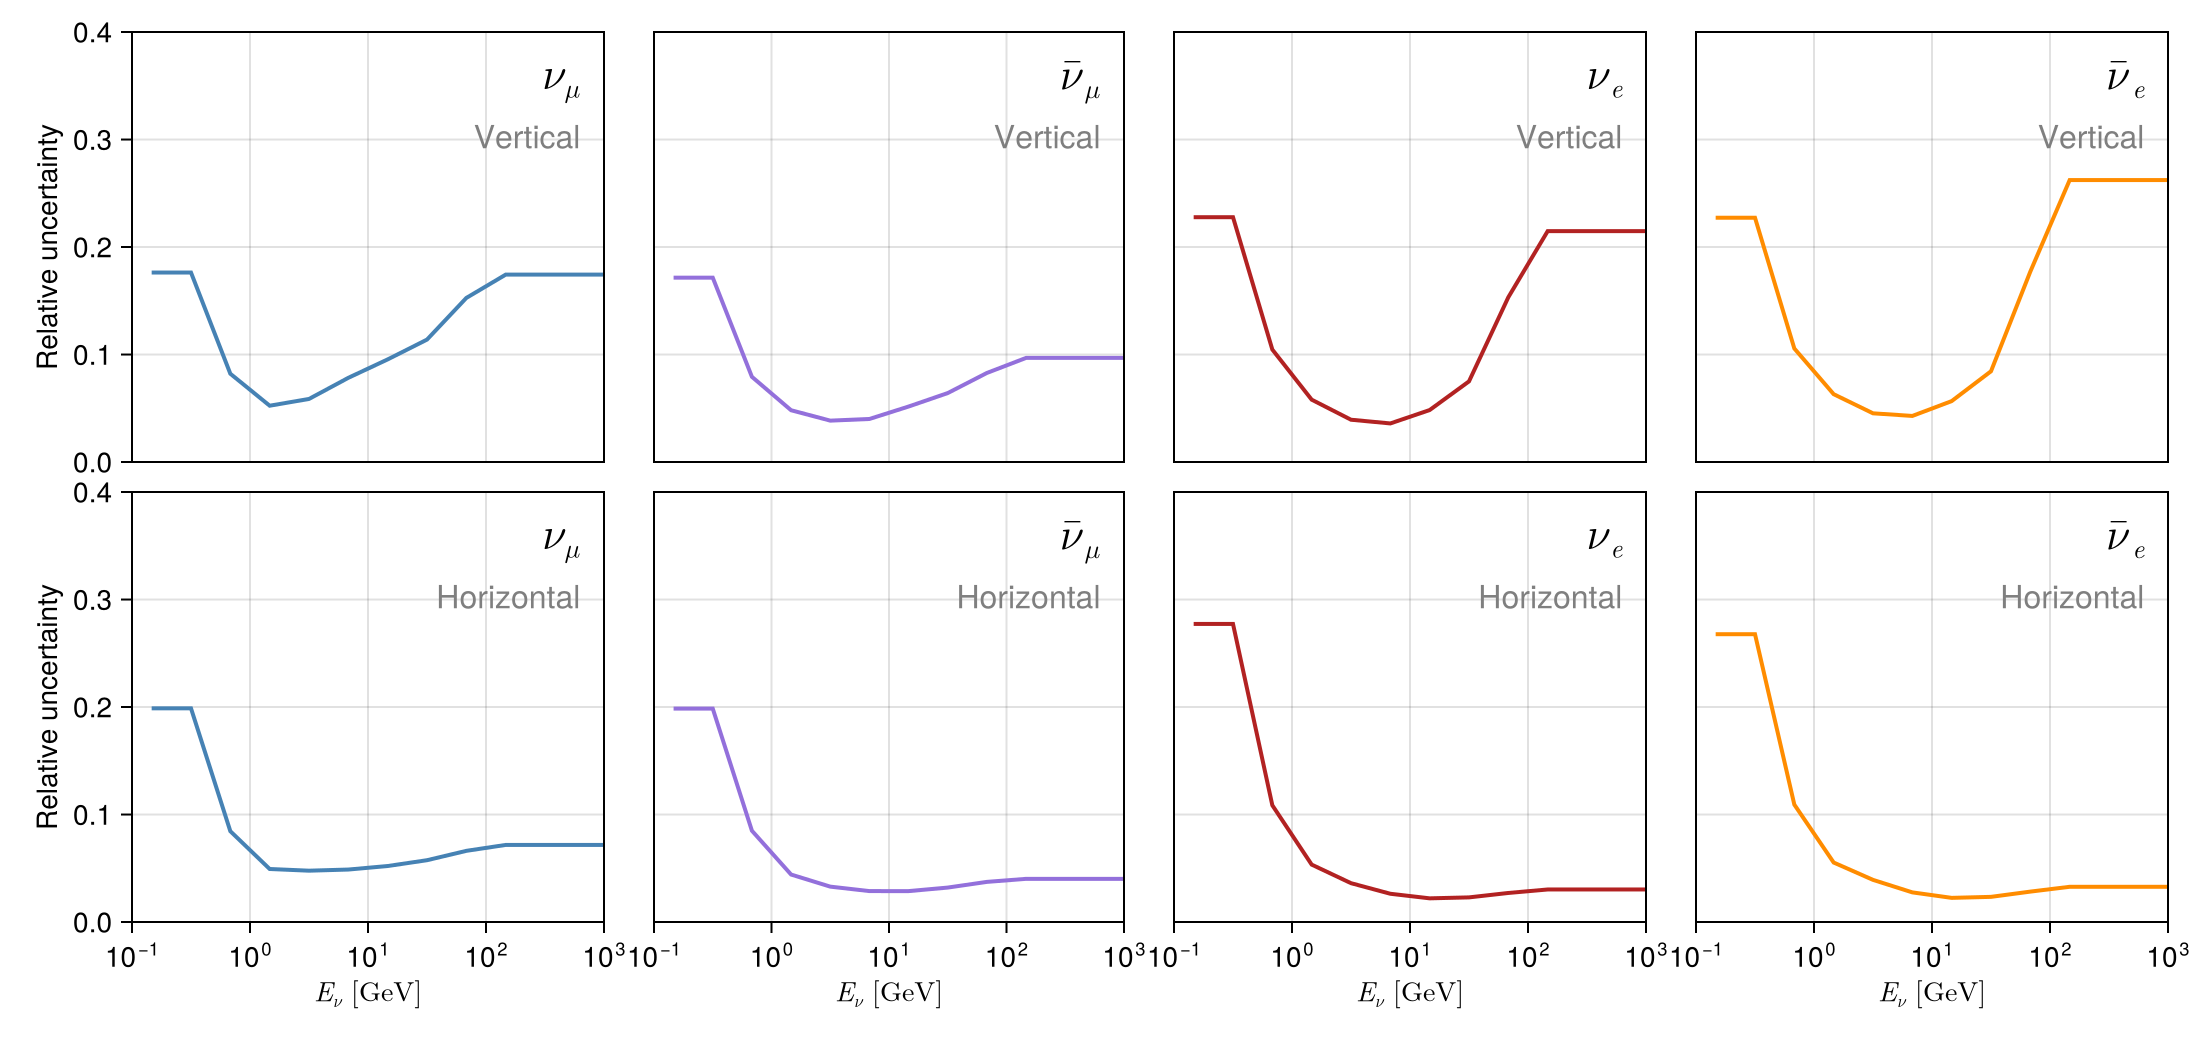

In [31]:
flux_list = [flux_νμ,     flux_aνμ,     flux_νe,     flux_aνe]
err_list  = [flux_νμ_err, flux_aνμ_err, flux_νe_err, flux_aνe_err]
labels    = [L"\nu_\mu", L"\bar\nu_\mu", L"\nu_e", L"\bar\nu_e"]
colors    = [:steelblue, :mediumpurple, :firebrick, :darkorange]

# Columns of the grid closest to vertical (|cosθ| = 1) and horizontal (cosθ = 0).
j_vert = argmax(abs.(cosθ))
j_hor  = argmin(abs.(cosθ))
rows   = [("Vertical", j_vert), ("Horizontal", j_hor)]

fig = Figure(size = (1100, 520))

for (r, (rowlabel, j)) in enumerate(rows), c in 1:4
    ax = Axis(fig[r, c];
              xscale = log10,
              limits = (1e-1, 1e3, 0.0, 0.4),
              xlabel = r == 2 ? L"E_\nu\ [\mathrm{GeV}]" : "",
              ylabel = c == 1 ? "Relative uncertainty" : "")

    rel_err = err_list[c][:, j] ./ flux_list[c][:, j]
    lines!(ax, E, rel_err; color = colors[c], linewidth = 2)

    text!(ax, 0.95, 0.95; text = labels[c], space = :relative,
          align = (:right, :top), fontsize = 22)
    text!(ax, 0.95, 0.80; text = rowlabel, space = :relative,
          align = (:right, :top), color = :gray50, fontsize = 16)

    r == 1 && hidexdecorations!(ax; grid = false, minorgrid = false)
    c > 1  && hideydecorations!(ax; grid = false, minorgrid = false)
end

colgap!(fig.layout, 25)
rowgap!(fig.layout, 15)

fig

These values were extracted from Fig. 16 of [arXiv2607.08310](https://arxiv.org/pdf/2607.08310). Since no values are provided for energies below 0.35 GeV or above 100 GeV, we assume a flat extrapolation beyond these energy boundaries (at least for now).

If you want to customize other parameters, you can do so as follows:

In [19]:
nuflux = produce_neutrino_flux(Dict{String, Any}(
    "model"              => :Cheng,
    "location"           => "icecube",
    "bin_centers_arrays" => (energies, cosθs)
));


solar_activity => minimum
location => icecube
model => Cheng
bin_centers_arrays => ([0.14677992676220697, 0.31622776601683794, 0.6812920690579614, 1.4677992676220695, 3.1622776601683795, 6.812920690579613, 14.677992676220697, 31.622776601683796, 68.12920690579612, 146.77992676220694, 316.22776601683796, 681.2920690579613, 1467.7992676220695, 3162.2776601683795, 6812.920690579613], -0.95:0.1:0.95)
return_uncertainties => false
season => all_year
angles_separation => averaged_ϕ
muon_propa_earth => with


#### Daemonflux model

Let's move to Daemonflux (also here, choosing "Daemonflux" instead of :Daemonflux for the "model" entry gives the same result), which works a bit different compared to Honda and Cheng:

In [38]:
produce_neutrino_flux(Dict{String, Any}(
    "model"              => :Daemonflux,
    "return_uncertainties" => true,
    "bin_centers_arrays" => (energies, cosθs)
))

flux_νe  = nuflux["Nue_flux"]
flux_νμ  = nuflux["NuMu_flux"]
flux_aνe = nuflux["AntiNue_flux"]
flux_aνμ = nuflux["AntiNuMu_flux"]

flux_νe_err  = nuflux["Nue_flux_err"]
flux_νμ_err  = nuflux["NuMu_flux_err"]
flux_aνe_err = nuflux["AntiNue_flux_err"]
flux_aνμ_err = nuflux["AntiNuMu_flux_err"]

E        = nuflux["Energies"]
cosθ     = nuflux["cosθs"]; 


flux_mode => total
model => Daemonflux
bin_centers_arrays => ([0.14677992676220697, 0.31622776601683794, 0.6812920690579614, 1.4677992676220695, 3.1622776601683795, 6.812920690579613, 14.677992676220697, 31.622776601683796, 68.12920690579612, 146.77992676220694, 316.22776601683796, 681.2920690579613, 1467.7992676220695, 3162.2776601683795, 6812.920690579613], -0.95:0.1:0.95)
return_uncertainties => true
params_df => nothing


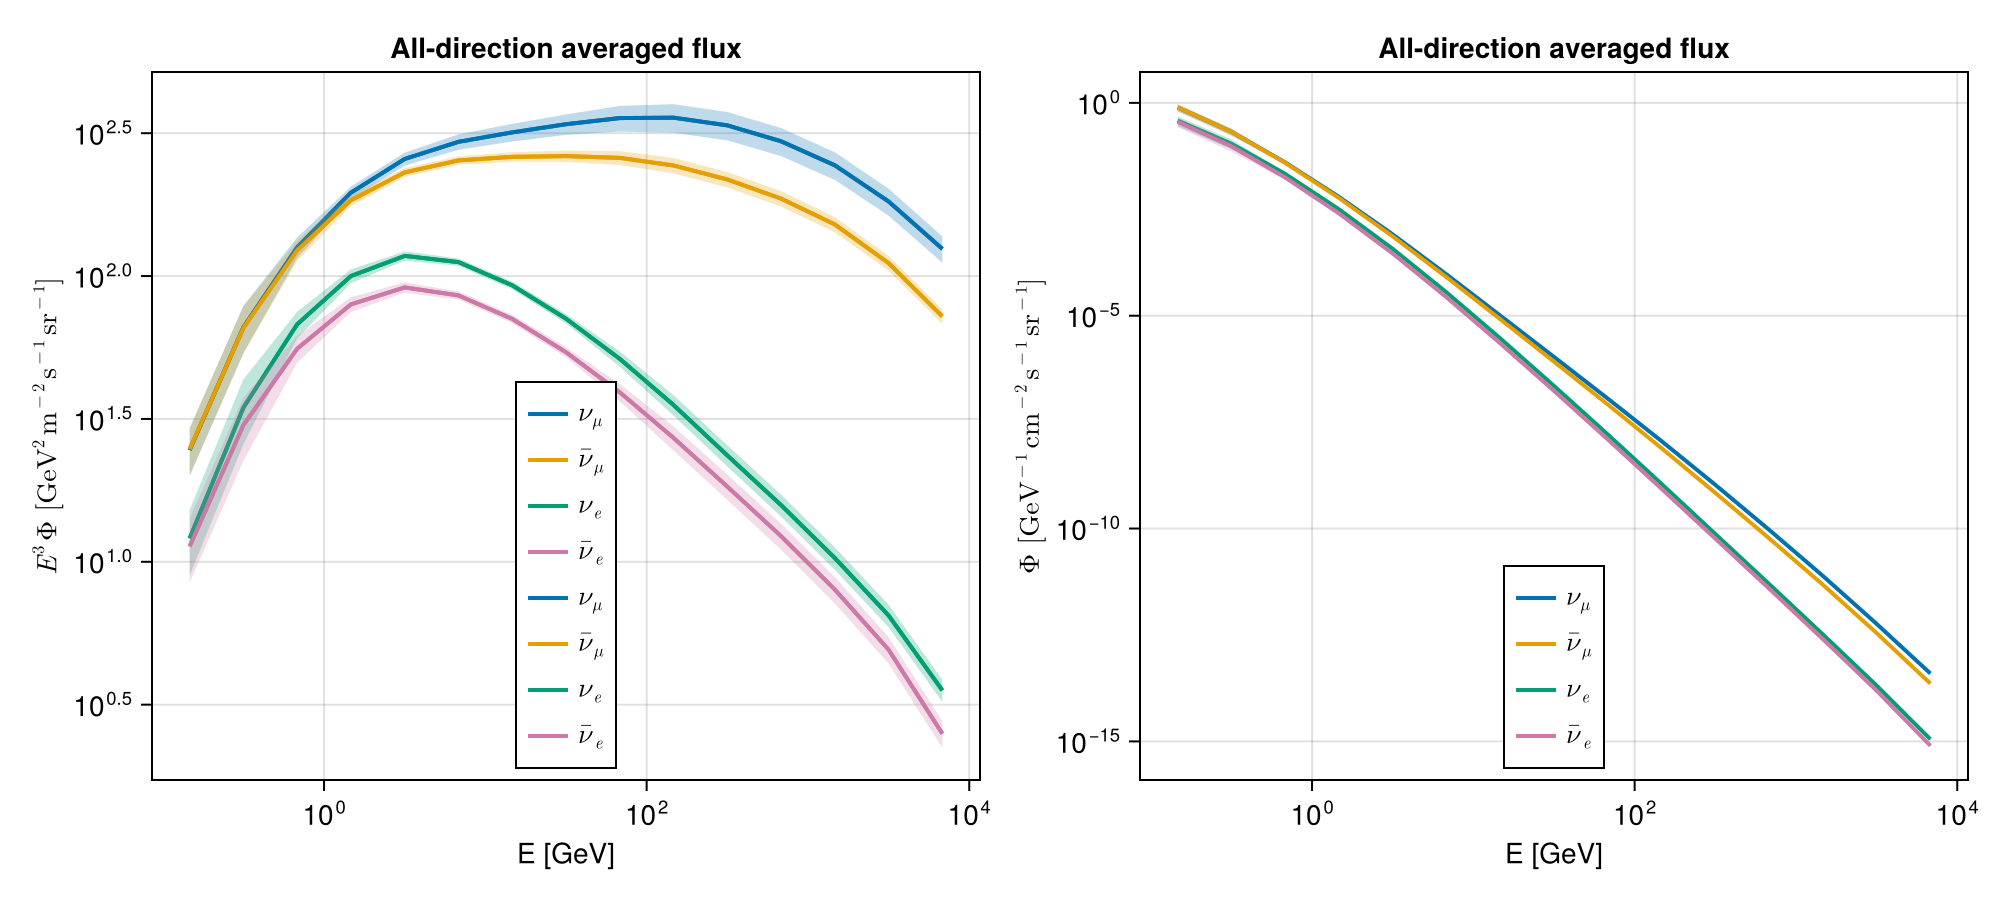

In [39]:

flux_list     = [flux_νμ,     flux_aνμ,     flux_νe,     flux_aνe]
flux_err_list = [flux_νμ_err, flux_aνμ_err, flux_νe_err, flux_aνe_err]
labels        = [L"\nu_\mu", L"\bar\nu_\mu", L"\nu_e", L"\bar\nu_e"]
colors        = Makie.wong_colors()[1:4]

fig3 = Figure(size = (1000, 450))

ax1 = Axis(fig3[1, 1]; 
           xscale = log10, yscale = log10,
           xlabel = "E [GeV]",
           ylabel = L"E^3\,\Phi\ [\mathrm{GeV^{2}\,m^{-2}\,s^{-1}\,sr^{-1}}]",
           title  = "All-direction averaged flux")
for (label, flux) in zip(labels, flux_list)
    lines!(ax1, E, E .^ 3 .* vec(mean(flux, dims = 2)); label = label, linewidth = 2)
end
for (label, flux, err, c) in zip(labels, flux_list, flux_err_list, colors)
    φ  = vec(mean(flux, dims = 2))
    Δφ = vec(mean(err,  dims = 2))
    band!(ax1, E, E .^ 3 .* (φ .- Δφ), E .^ 3 .* (φ .+ Δφ); color = (c, 0.25))
    lines!(ax1, E, E .^ 3 .* φ; label = label, linewidth = 2, color = c)
end
axislegend(ax1; position = :cb)

ax2 = Axis(fig3[1, 2]; 
           xscale = log10, yscale = log10,
           xlabel = "E [GeV]",
           ylabel = L"\Phi\ [\mathrm{GeV^{-1}\,cm^{-2}\,s^{-1}\,sr^{-1}}]",
           title  = "All-direction averaged flux")
for (label, flux, err, c) in zip(labels, flux_list, flux_err_list, colors)
    φ  = vec(mean(flux, dims = 2)) ./ 10000.
    Δφ = vec(mean(err,  dims = 2)) ./ 10000.
    band!(ax2, E, φ .- Δφ, φ .+ Δφ; color = (c, 0.25))
    lines!(ax2, E, φ; label = label, linewidth = 2, color = c)
end
axislegend(ax2; position = :cb)

fig3
